In [1]:
from pydantic import BaseModel,Field
from typing import List,TypedDict,Literal
import time



In [3]:
from langchain_community.vectorstores import FAISS
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.prompts import HumanMessagePromptTemplate,ChatPromptTemplate
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph ,START,END
from langchain_ollama import ChatOllama


In [4]:
docs=(
    PyPDFLoader(r"C:\Users\PC\Downloads\Product_and_Pricing.pdf").load()
    +PyPDFLoader(r"C:\Users\PC\Downloads\Company_Policies.pdf").load()
    +PyPDFLoader(r"C:\Users\PC\Downloads\Company_Profile.pdf").load()
    
)

In [10]:
chunks=RecursiveCharacterTextSplitter(chunk_size=60,chunk_overlap=5).split_documents(docs)
print(len(chunks))

160


In [7]:
print(len(docs))

8


In [11]:
embedding=HuggingFaceEmbeddings(model_name='all-MiniLM-L6-v2')

C:\Users\PC\AppData\Local\Temp\ipykernel_7612\3151999145.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding=HuggingFaceEmbeddings(model_name='all-MiniLM-L6-v2')


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [12]:
vector_store=FAISS.from_documents(docs,embedding)


In [14]:
retrivre=vector_store.as_retriever(
    search_type="similarity",
    search_kwargs={'k':4}
)

In [25]:
print(retrivre.invoke("what is the product of nexAI?")[3].page_content)

Founder
Aarav Mehta founded NexaAI after over 10 years of experience in enterprise data platforms and
cloud infrastructure.
He previously worked with global consulting firms where he led multiple large-scale digital
transformation projects.
Leadership Team
The leadership team brings experience across AI engineering, product management, and business
operations.

Aarav Mehta – CEO & Founder

Riya Kapoor – CTO (Distributed systems & AI platforms)

Kunal Sharma – Head of Product

Neha Verma – Head of Operations & HR

Siddharth Rao – Head of Sales & Partnerships


In [31]:
llm=ChatOllama(model='qwen2.5:3b',temperature=0.4)

In [28]:
while True:
    quer=input("inter your query: ")
    if quer.lower()=='exit':
        break
    result=retrivre.invoke(quer)
    for i,doc in enumerate(result):
        print(doc.page_content)
        print("*"*20)
        


Founder
Aarav Mehta founded NexaAI after over 10 years of experience in enterprise data platforms and
cloud infrastructure.
He previously worked with global consulting firms where he led multiple large-scale digital
transformation projects.
Leadership Team
The leadership team brings experience across AI engineering, product management, and business
operations.

Aarav Mehta – CEO & Founder

Riya Kapoor – CTO (Distributed systems & AI platforms)

Kunal Sharma – Head of Product

Neha Verma – Head of Operations & HR

Siddharth Rao – Head of Sales & Partnerships
********************
NexaAI Solutions – Company Profile
Company Overview
NexaAI Solutions Pvt. Ltd. is a business-focused artificial intelligence company founded in 2021.
The company specializes in building enterprise-ready AI systems for knowledge management,
analytics, and automation.
NexaAI primarily serves mid-sized and large organizations across technology, finance, healthcare,
and education sectors.

Founded: 2021

Head

In [27]:
var='komal is very beautyfull girl'
print(var.lower())

komal is very beautyfull girl


In [51]:
query="who is founder of nexa ai?"
db=retrivre.invoke(query)
context=" ".join([doc.page_content for doc in db])
pt=f"you are helfull ai assitent answer the query-{query} only from the provide context- {context} if query is out of provide document say I DO NOT KNOW."
response=llm.invoke(pt)
print(response.content)

Based on the provided context, Aarav Mehta is the founder of NexaAI. The document states that "Founder Aarav Mehta founded NexaAI after over 10 years of experience in enterprise data platforms and cloud infrastructure."


In [37]:
print(response.content)

I DO NOT KNOW. The provided document does not contain any information about Riya Capoor.


In [133]:
from langchain_core.documents import Document
from pydantic import BaseModel
class state(TypedDict):
    question:str
    need_retrival:bool
    docs:List[Document]

    ans:str

In [134]:
class Retriverdesion(BaseModel):
    should_retrive:bool=Field(
        ...,
        description='True if external documents are need to answer reliably.else Flase '
    )


decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

In [135]:
should_retrive_llm=llm.with_structured_output(Retriverdesion)

def decide_retrival(state:state):
    dection:Retriverdesion=should_retrive_llm.invoke(decide_retrieval_prompt.format_messages(question=state['question']))

    return {'need_retrival':dection.should_retrive}




In [136]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

In [137]:
def generate_direct(state:state):
    out=llm.invoke(direct_generation_prompt.format_messages(question=state['question']))

    return {
        'ans':out.content
    }

In [138]:
def retrive(state:state):
    return {'docs':retrivre.invoke(state['question'])}

In [139]:
def route_after_decide(state:state)->Literal['generate_direct','retrive']:
    if state['need_retrival']:
        return 'retrive'
    return "generate_direct"


In [140]:
g=StateGraph(state)

In [141]:
# 1. Update node names to match the function's expected output
g.add_node('decide_retriver', decide_retrival)
g.add_node('generate_direct', generate_direct)  # Fixed typo ('genrated' -> 'generate')
g.add_node('retrive', retrive)

g.add_edge(START, 'decide_retriver')

g.add_conditional_edges(
    'decide_retriver',
    route_after_decide,
    {
        # The key must EXACTLY match what route_after_decide returns ('generate_direct')
        'generate_direct': 'generate_direct',    # Fixed typo here
        'retrive': 'retrive'
    }
)

# 2. Update the closing edges to match the corrected node name
g.add_edge('generate_direct', END)               # Fixed typo here
g.add_edge('retrive', END)

app = g.compile()


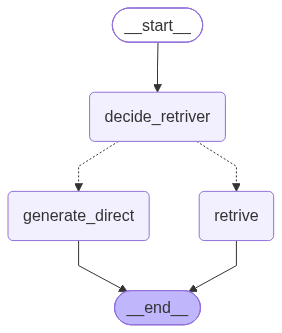

In [142]:
app

In [143]:
result=app.invoke(
    {
    'question':'who is founder of nexa ai?',
    'need_retrival':False,
    'docs':[],
    'ans':'',
    })

In [159]:
print(result)

{'question': 'who is founder of nexa ai?', 'need_retrival': True, 'docs': [Document(id='4bafb310-ef94-4305-b7b6-f5c727681503', metadata={'producer': 'ReportLab PDF Library - www.reportlab.com', 'creator': '(unspecified)', 'creationdate': '2026-02-14T13:07:17+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-02-14T13:07:17+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': 'C:\\Users\\PC\\Downloads\\Company_Profile.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='Founder\nAarav Mehta founded NexaAI after over 10 years of experience in enterprise data platforms and\ncloud infrastructure.\nHe previously worked with global consulting firms where he led multiple large-scale digital\ntransformation projects.\nLeadership Team\nThe leadership team brings experience across AI engineering, product management, and business\noperations.\n\x7f\nAarav Mehta – CEO & Founder\n\x7f\nRiya Kapoor – CTO (Distributed systems & AI p

In [162]:
print(result["ans"])